# OPTICS from scratch

This notebook rebuilds what the library lab [`optics_hdbscan_lab.ipynb`](optics_hdbscan_lab.ipynb) uses, with nothing but NumPy, and checks each
result against scikit-learn or SciPy on the same data. The theory is in [README §6](../../README.md#6-optics-and-hdbscan).

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers), then run top to bottom (**Run All**). Later cells reuse functions
   from earlier ones.
2. Each section has the same shape: the algorithm in plain steps (markdown) → the code, commented line by line →
   a **comparison with the library** → a "How to read this" box.
3. Boxes titled **Implementation hurdle** show a real problem you hit when writing this yourself, demonstrated on a
   small case and then fixed.
4. scikit-learn and SciPy are imported **only to check** our answers. No internet needed.

| Section | Algorithm | Checked against |
|---|---|---|
| [OPTICS](#sec-5) | OPTICS and extracting DBSCAN clusters from it | `sklearn.cluster.OPTICS`, `cluster_optics_dbscan` |
| [Summary](#summary) | what matched, and the hurdles | |

**Distance helper** (defined in the first code cell): `exact_distances(X)` subtracts the points directly, so
distances that should tie really do tie. The first code cell also re-creates the DBSCAN notebook's data.

In [1]:
import heapq
import time

import numpy as np
import matplotlib.pyplot as plt

# scikit-learn / SciPy are imported ONLY to check our answers against theirs; every algorithm below is plain NumPy.
from sklearn.cluster import DBSCAN, OPTICS, cluster_optics_dbscan
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def exact_distances(X):
    """All point-to-point distances computed from the differences themselves (n x n x d in memory, fine for a few
    thousand points). Slower than the |a|² - 2a·b + |b|² trick k-means uses, but exact to the last digit, which
    matters when distances TIE (see the ties hurdle in the hierarchical from-scratch notebook)."""
    return np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))


def plot_clusters(ax, X, labels, title):
    """Scatter 2-D points coloured by cluster label; label -1 (noise) as grey crosses."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")


# The data from the DBSCAN notebook: two moons plus 20 stray points spread over the same area
X_db, _ = make_moons(400, noise=0.07, random_state=SEED)
X_db = np.vstack([X_db, np.random.default_rng(SEED).uniform([-1.5, -1], [2.5, 1.5], size=(20, 2))])

<a id="sec-5"></a>

## OPTICS

**README §6.** OPTICS answers "what would DBSCAN give at *every* eps?" in one pass.

* **Core distance** of $p$: distance to its `min_samples`-th nearest neighbour, counting $p$ itself. The smallest
  eps at which $p$ would be a core point.
* **Reachability distance** of $o$ from $p$: $\max\big(\text{core distance}(p),\ d(p, o)\big)$.
* **The loop:** take the unvisited point with the smallest reachability so far (the lowest index if several tie, or if
  all are still infinite, which is how a new region starts). Record it in the **ordering**. If it is a core point,
  lower the reachability of each unvisited point to its reachability through this point, when that is smaller.

Plotting reachability in visiting order gives the reachability plot: valleys are clusters. `clusters_at_eps` turns one
horizontal cut into DBSCAN-style labels: walking in order, a point with reachability above eps that is itself a core
point at that eps starts a new cluster; a point that is neither is noise. Same data as the [DBSCAN from-scratch notebook](../03-dbscan/dbscan_from_scratch.ipynb) (two moons plus 20 stray points, re-created in the first code cell).

same ordering: True | same predecessors: True
largest difference: reachability 4.996003610813204e-16 | core distance 4.996003610813204e-16
time: ours 0.008 s, scikit-learn 0.109 s
cut at eps 0.100:  5 clusters,   8% noise | same as sklearn's cut: True | agreement with DBSCAN at that eps: ARI 0.998
cut at eps 0.164:  2 clusters,   3% noise | same as sklearn's cut: True | agreement with DBSCAN at that eps: ARI 1.000
cut at eps 0.500:  1 clusters,   1% noise | same as sklearn's cut: True | agreement with DBSCAN at that eps: ARI 1.000


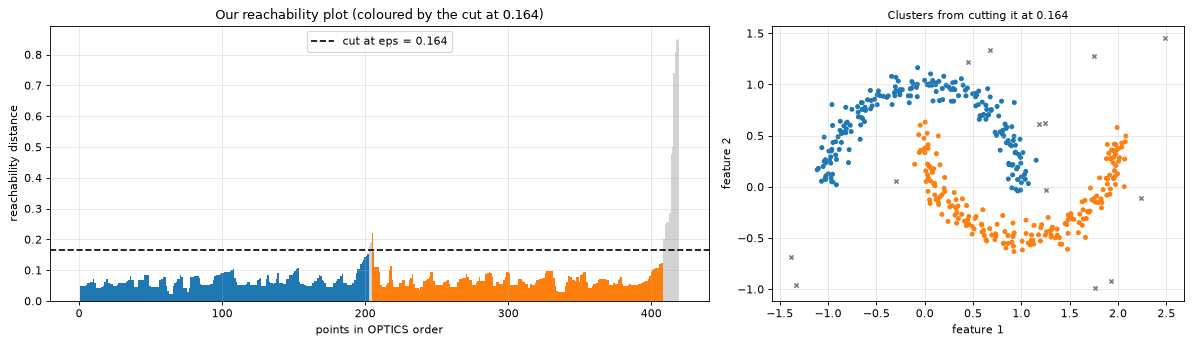

In [2]:
def optics(X, min_samples, max_eps=np.inf):
    """OPTICS. Returns (ordering, reachability, core_distances, predecessor), each indexed like scikit-learn.

    core distance(p)    = distance to p's min_samples-th nearest neighbour, counting p itself
    reachability(o, p)  = max(core distance(p), d(p, o))
    Loop: take the unvisited point with the SMALLEST reachability so far (the lowest index if several tie, or if
    all are still infinite), record it, and lower the reachability of its unvisited neighbours through it."""
    n = len(X)
    D = exact_distances(X)
    core_dist = np.sort(D, axis=1)[:, min_samples - 1]           # column 0 is the point itself (distance 0)
    core_dist[core_dist > max_eps] = np.inf                       # too far: not a core point at any eps <= max_eps
    reach = np.full(n, np.inf)                                    # best reachability found so far for each point
    predecessor = np.full(n, -1)                                  # which point gave that reachability
    visited = np.zeros(n, dtype=bool)
    ordering = []
    for _ in range(n):
        candidates = np.flatnonzero(~visited)
        p = candidates[np.argmin(reach[candidates])]              # argmin picks the lowest index among ties
        visited[p] = True
        ordering.append(p)
        if np.isinf(core_dist[p]):
            continue                                              # not a core point: it can't reach anyone
        others = np.flatnonzero(~visited & (D[p] <= max_eps))     # unvisited points within max_eps of p
        through_p = np.maximum(core_dist[p], D[p, others])        # their reachability if reached from p
        better = through_p < reach[others]                        # only ever lower a reachability
        reach[others[better]] = through_p[better]
        predecessor[others[better]] = p
    return np.array(ordering), reach, core_dist, predecessor


def clusters_at_eps(ordering, reach, core_dist, eps):
    """DBSCAN-style clusters from an OPTICS run, by cutting the reachability plot at height eps.
    Walking in OPTICS order, a point that is far from everything visited so far (reach > eps) but is itself a
    core point at this eps starts a new cluster; a point that is neither close nor core is noise."""
    far = reach > eps
    core_here = core_dist <= eps
    labels = np.zeros(len(reach), dtype=int)
    labels[ordering] = np.cumsum(far[ordering] & core_here[ordering]) - 1   # cluster number goes up at each start
    labels[far & ~core_here] = -1
    return labels


t0 = time.perf_counter(); order, reach, core_d, pred = optics(X_db, min_samples=5); t_ours = time.perf_counter() - t0
t0 = time.perf_counter(); reference = OPTICS(min_samples=5).fit(X_db); t_sk = time.perf_counter() - t0
finite = ~np.isinf(reach)
print("same ordering:", np.array_equal(order, reference.ordering_),
      "| same predecessors:", np.array_equal(pred, reference.predecessor_))
print("largest difference: reachability", np.abs(reach[finite] - reference.reachability_[finite]).max(),
      "| core distance", np.abs(core_d - reference.core_distances_).max())
print(f"time: ours {t_ours:.3f} s, scikit-learn {t_sk:.3f} s")
for eps in [0.1, 0.164, 0.5]:
    ours = clusters_at_eps(order, reach, core_d, eps)
    theirs = cluster_optics_dbscan(reachability=reference.reachability_, core_distances=reference.core_distances_,
                                   ordering=reference.ordering_, eps=eps)
    direct = DBSCAN(eps=eps, min_samples=5).fit_predict(X_db)
    print(f"cut at eps {eps:5.3f}: {ours.max() + 1:2d} clusters, {np.mean(ours == -1):4.0%} noise | same as sklearn's "
          f"cut: {np.array_equal(ours, theirs)} | agreement with DBSCAN at that eps: ARI {adjusted_rand_score(direct, ours):.3f}")
assert np.array_equal(order, reference.ordering_)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
labels_cut = clusters_at_eps(order, reach, core_d, 0.164)
colors = ["lightgray" if label == -1 else plt.cm.tab10(label % 10) for label in labels_cut[order]]
axes[0].bar(range(len(order)), np.where(np.isinf(reach[order]), np.nan, reach[order]), color=colors, width=1.0)
axes[0].axhline(0.164, color="black", ls="--", label="cut at eps = 0.164")
axes[0].set_xlabel("points in OPTICS order"); axes[0].set_ylabel("reachability distance")
axes[0].set_title("Our reachability plot (coloured by the cut at 0.164)"); axes[0].legend()
plot_clusters(axes[1], X_db, labels_cut, "Clusters from cutting it at 0.164")
plt.tight_layout(); plt.show()

> **How to read this**
> * Same **ordering** and same **predecessors** (which point each one was reached from) as scikit-learn; reachability
>   and core distances agree to **5e-16**.
> * Our version is faster here (see the printed times) only because it holds the full 420 × 420 distance matrix in memory.
>   scikit-learn uses a neighbour search instead, which scales to data where an n × n matrix wouldn't fit.
> * **Cutting our reachability plot** at eps = 0.1, 0.164 and 0.5 gives exactly scikit-learn's `cluster_optics_dbscan`
>   labels, and matches running DBSCAN at that eps: ARI **1.000** at 0.164 and 0.5, **0.998** at 0.1 (a border point or
>   two can land differently). At 0.1 the moons shatter into 5 clusters; at 0.5 they merge into 1.

> **Implementation hurdle — the "smallest reachability so far" queue.** Textbook OPTICS keeps unvisited points in a
> priority queue (a heap) and *lowers* a point's key when a better reachability is found. Python's `heapq` has no
> "lower a key" operation. The standard workaround: push a **new** entry with the lower value and, when popping, skip
> entries whose point was already visited ("lazy deletion"). Ties must also be broken the same way (by point index) to
> reproduce the same ordering.

In [3]:
def optics_heap(X, min_samples):
    """The same OPTICS loop, but the next point comes from a heap (priority queue) instead of an argmin over all
    unvisited points. Python's heapq can't lower a key, so a lowered reachability is pushed as a NEW entry and
    stale entries (for points already visited) are skipped when popped ("lazy deletion")."""
    n = len(X)
    D = exact_distances(X)
    core_dist = np.sort(D, axis=1)[:, min_samples - 1]
    reach = np.full(n, np.inf)
    visited = np.zeros(n, dtype=bool)
    ordering, heap, next_start = [], [], 0
    while len(ordering) < n:
        while heap and visited[heap[0][1]]:
            heapq.heappop(heap)                                   # throw away stale entries
        if heap:
            _, p = heapq.heappop(heap)                            # smallest (reachability, index) pair
        else:                                                     # nothing reachable: start at the next unvisited
            while visited[next_start]:
                next_start += 1
            p = next_start
        visited[p] = True
        ordering.append(p)
        others = np.flatnonzero(~visited)
        through_p = np.maximum(core_dist[p], D[p, others])
        for q, r in zip(others[through_p < reach[others]], through_p[through_p < reach[others]]):
            reach[q] = r
            heapq.heappush(heap, (r, q))                          # ties broken by index, like argmin
    return np.array(ordering), reach


t0 = time.perf_counter(); order_heap, reach_heap = optics_heap(X_db, 5); t_heap = time.perf_counter() - t0
print("heap version: same ordering as the argmin version:", np.array_equal(order_heap, order),
      "| same reachability:", np.allclose(np.nan_to_num(reach_heap, posinf=0), np.nan_to_num(reach, posinf=0)))
print(f"time on {len(X_db)} points: argmin version {t_ours:.3f} s, heap version {t_heap:.3f} s")

heap version: same ordering as the argmin version: True | same reachability: True
time on 420 points: argmin version 0.008 s, heap version 0.013 s


> **How to read this**
> * The heap version gives the **same ordering and reachability** as the argmin version (and therefore as
>   scikit-learn).
> * It isn't faster here (see the printed times): with a full distance matrix both versions look at every unvisited point
>   at every step, so both cost about $n^2$, and NumPy's `argmin` is quicker than a Python heap loop. The heap pays off
>   when each point only has a few neighbours to update (a neighbour index plus a finite `max_eps`).

---

<a id="summary"></a>

## Summary

| Section | Our implementation | Matches the library? | Hurdle shown |
|---|---|---|---|
| [OPTICS](#sec-5) | OPTICS, `clusters_at_eps` | ✔ identical ordering, reachability, predecessors and cuts | priority queue without decrease-key |